In [ ]:
#sara costa 17_03_2025
#data: neck 
#fig4a

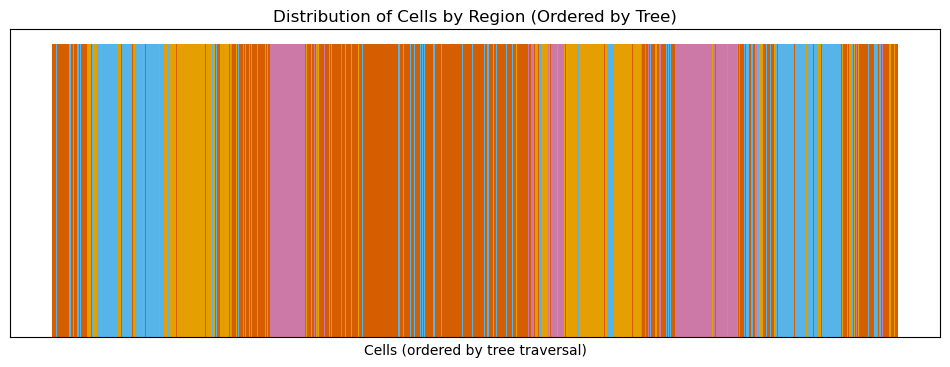

In [ ]:
#good to use - takes 2 min to run 

import matplotlib.pyplot as plt
import seaborn as sns
from ete3 import Tree

# Load tree from file
tree_file = "tree_17_03_2025"  # Update with your actual file path
t = Tree(tree_file, format=1)  # format=1 assumes branch lengths and support values are present

region_colors = {
    "neck15": "#E69F00",  # orange (can be swapped with yellow if you want softer)
    "neck17": "#56B4E9",  # sky blue
    "neck18": "#D55E00",  # reddish
    "neck16": "#CC79A7"   # purple/magenta
}


# Get the leaf order by pre-order traversal
leaves = [leaf.name for leaf in t.iter_leaves()]

# Extract region labels
regions = [leaf.split("_")[0] for leaf in leaves]  # Extract "neck15", "neck16", etc.
colors = [region_colors.get(region, "black") for region in regions]  # Get corresponding colors

# Create the histogram (bar plot)
plt.figure(figsize=(12, 4))
#sns.barplot(x=range(len(leaves)), y=[1] * len(leaves), hue=regions, palette=region_colors, dodge=False, legend=False, alpha=1, 
 #   edgecolor=None, rasterized=True)
for i, region in enumerate(regions):
    plt.bar(i, 1, color=region_colors[region], width=1.0, edgecolor="none", rasterized=True)

# Format the plot
plt.xticks([])  # Hide x-axis labels (too many)
plt.yticks([])  # Hide y-axis labels (we only care about color distribution)
plt.xlabel("Cells (ordered by tree traversal)")
plt.ylabel("")
plt.title("Distribution of Cells by Region (Ordered by Tree)")

# Remove legend title
#plt.legend(title="Region")
plt.savefig("trees/distribution_by_region_unfiltered.png",
            format="png", dpi=1000, bbox_inches="tight", facecolor="white")
plt.savefig("trees/distribution_by_region_unfiltered.pdf",
            format="pdf", dpi=1000, bbox_inches="tight", facecolor="white")

# Show the plot
#plt.show()


In [3]:
from matplotlib.patches import Patch
# Define mapping of regions to biological labels
region_mapping = {
    "neck15": "Normal laryngeal mucosal epithelia (N)",
    "neck17": "Margins of cancer (R)",
    "neck18": "Carcinoma in situ (T)",
    "neck16": "Lymph nodes metastasis (L)"
}

legend_order = ["neck15", "neck17", "neck18", "neck16"]  # N, R, T, L

legend_elements = [
    Patch(facecolor=region_colors[key], label=region_mapping[key])
    for key in legend_order
]

plt.figure(figsize=(6, 2))
plt.legend(handles=legend_elements, loc="center", frameon=False, ncol=2)
plt.axis("off")

# Save standalone legend
plt.savefig("trees/region_legend.pdf", format="pdf", dpi=300, bbox_inches="tight")
plt.close()

In [5]:
from ete3 import Tree

# Load the tree from a file (or a string)
tree = Tree("tree_17_03_2025", format=1)  # Ensure format=1 to preserve internal node names

# Define the new root label
new_root_label = "neck17_ATGAGTCCAAATGAGT-1"

# Find the node with the given label
new_root = tree.search_nodes(name=new_root_label)

if new_root:
    tree.set_outgroup(new_root[0])  # Reroot the tree
    tree.ladderize()  # Optional: Order branches for better visualization

    # Save or print the new tree
    tree.write(format=1, outfile="rerooted_tree.nwk")
    print("Tree rerooted successfully!")
else:
    print("Label not found in tree.")


Tree rerooted successfully!


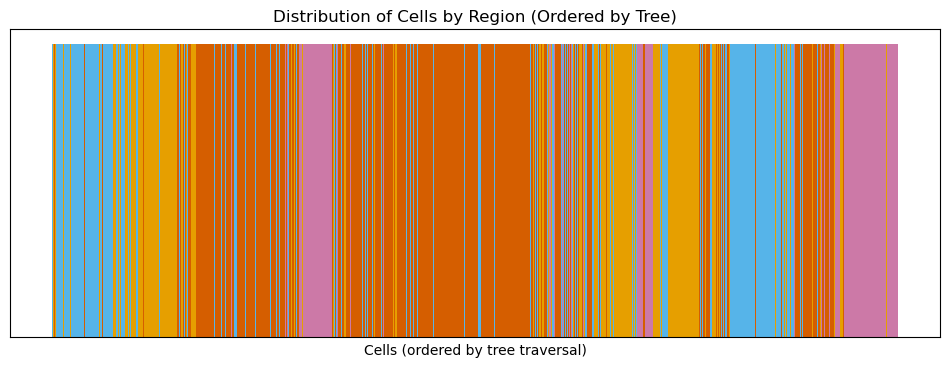

In [ ]:
#good to use - takes 2 min to run 

import matplotlib.pyplot as plt
import seaborn as sns
from ete3 import Tree

# Load tree from file
tree_file = "rerooted_tree.nwk"  # Update with your actual file path
t = Tree(tree_file, format=1)  # format=1 assumes branch lengths and support values are present


# Get the leaf order by pre-order traversal
leaves = [leaf.name for leaf in t.iter_leaves()]

# Extract region labels
regions = [leaf.split("_")[0] for leaf in leaves]  # Extract "neck15", "neck16", etc.
colors = [region_colors.get(region, "black") for region in regions]  # Get corresponding colors

# Create the histogram (bar plot)
plt.figure(figsize=(12, 4))
#sns.barplot(x=range(len(leaves)), y=[1] * len(leaves), hue=regions, palette=region_colors, dodge=False, legend=False, alpha=1, 
 #   edgecolor=None, rasterized=True)
for i, region in enumerate(regions):
    plt.bar(i, 1, color=region_colors[region], width=1.0, edgecolor="none", rasterized=True)

# Format the plot
plt.xticks([])  # Hide x-axis labels (too many)
plt.yticks([])  # Hide y-axis labels (we only care about color distribution)
plt.xlabel("Cells (ordered by tree traversal)")
plt.ylabel("")
plt.title("Distribution of Cells by Region (Ordered by Tree)")

# Remove legend title
#plt.legend(title="Region")
plt.savefig("trees/distribution_by_region_after_root_bef_filt_after_rooting.pdf",
            format="pdf", dpi=300, bbox_inches="tight", facecolor="white")

# Show the plot
#plt.show()


In [16]:
#experiment 18_03:
#get the mutations (A or H) that occur in the normal tissue (those will be considered germline polymorphisms and we want to filter them) - if they occur in more than 30/50% of the cells remove them from all the data - re-do a genotype file - run fasttree again, get a new tree 

In [10]:
import pandas as pd
import subprocess

# ---- Step 1: Load the Genotype File ----
genotype_file = "genotypes.txt"  # Update if needed
output_filtered_file = "filtered_genotype.txt"
#output_tree_file = "new_tree.nwk"

# Load data (assuming it's tab-separated with rows as mutations and columns as cells)
df = pd.read_csv(genotype_file, sep="\t", index_col=0)

# ---- Step 2: Identify Normal Tissue Cells ----
normal_tissue_cols = [col for col in df.columns if col.startswith("neck15_")]  # Detect normal cells

# Count occurrences of A or H in normal tissue
mutation_counts = (df[normal_tissue_cols] == "A").sum(axis=1) #+ (df[normal_tissue_cols] == "H").sum(axis=1)
print(mutation_counts)
print(len(normal_tissue_cols))


# Compute fraction of affected normal cells
fraction = mutation_counts / len(normal_tissue_cols)

# Filter out mutations occurring in >40% of normal cells (remove from all cells)
filtered_df = df.loc[fraction <= 0.6]

# Count mutations removed
num_removed = df.shape[0] - filtered_df.shape[0]

# ---- Step 3: Save the Filtered Genotype File ----
filtered_df.to_csv(output_filtered_file, sep="\t", index=True)  # Keeps mutation row names

# ---- Step 4: Run FastTree ----
#fasttree_cmd = f"/Applications/FastTree -nt {output_filtered_file} > {output_tree_file}"
#subprocess.run(fasttree_cmd, shell=True, check=True)

# ---- Print Summary ----
print(f"Filtered genotype file saved as {output_filtered_file}")
#print(f"New tree generated: {output_tree_file}")
print(f"Mutations removed: {num_removed}")



Site
chr11_65501978_G_A       0
chr9_128342763_T_G       0
chr18_12785558_C_T    5283
chr2_241095731_G_T    4280
chr11_82824419_G_A    6460
                      ... 
chr4_189940928_T_C       0
chr19_38304255_T_C       0
chr2_176201018_G_C    3267
chr19_44821259_C_T    1257
chr6_35321669_T_C     5197
Length: 1001, dtype: int64
11628
Filtered genotype file saved as filtered_genotype.txt
Mutations removed: 270


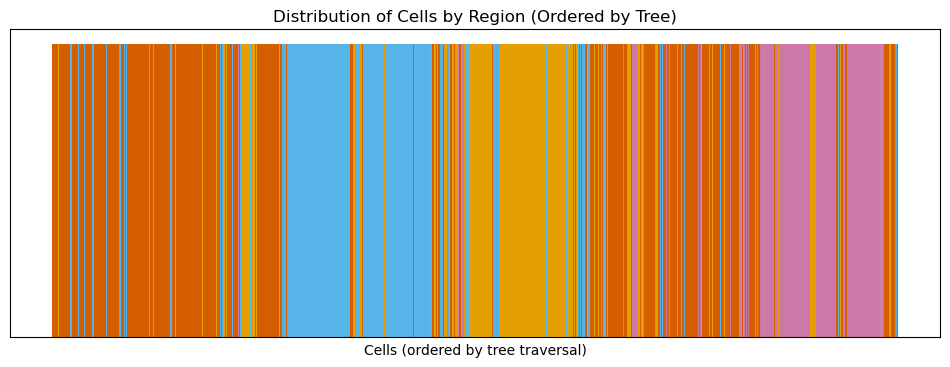

In [8]:
#good to use - takes 2 min to run 

import matplotlib.pyplot as plt
import seaborn as sns
from ete3 import Tree

# Load tree from file
tree_file = "less_germline/tree"  # Update with your actual file path
t = Tree(tree_file, format=1)  # format=1 assumes branch lengths and support values are present


# Get the leaf order by pre-order traversal
leaves = [leaf.name for leaf in t.iter_leaves()]

# Extract region labels
regions = [leaf.split("_")[0] for leaf in leaves]  # Extract "neck15", "neck16", etc.
colors = [region_colors.get(region, "black") for region in regions]  # Get corresponding colors

# Create the histogram (bar plot)
plt.figure(figsize=(12, 4))
#sns.barplot(x=range(len(leaves)), y=[1] * len(leaves), hue=regions, palette=region_colors, dodge=False, legend=False, alpha=1, 
 #   edgecolor=None, rasterized=True)
for i, region in enumerate(regions):
    plt.bar(i, 1, color=region_colors[region], width=1.0, edgecolor="none", rasterized=True)

# Format the plot
plt.xticks([])  # Hide x-axis labels (too many)
plt.yticks([])  # Hide y-axis labels (we only care about color distribution)
plt.xlabel("Cells (ordered by tree traversal)")
plt.ylabel("")
plt.title("Distribution of Cells by Region (Ordered by Tree)")

# Remove legend title
#plt.legend(title="Region")
plt.savefig("trees/distribution_by_region_after_filt.pdf",
            format="pdf", dpi=300, bbox_inches="tight", facecolor="white")

#plt.legend(title="Region")
plt.savefig("trees/distribution_by_region_after_filt.png",
            format="png", dpi=1000, bbox_inches="tight", facecolor="white")

# Show the plot
#plt.show()


In [14]:
from ete3 import Tree

# Load the tree from a file (or a string)
tree = Tree("less_germline/tree", format=1)  # Ensure format=1 to preserve internal node names

# Define the new root label
new_root_label = "neck17_ATGAGTCCAAATGAGT-1"

# Find the node with the given label
new_root = tree.search_nodes(name=new_root_label)

if new_root:
    tree.set_outgroup(new_root[0])  # Reroot the tree
    tree.ladderize()  # Optional: Order branches for better visualization

    # Save or print the new tree
    tree.write(format=1, outfile="rerooted_tree_no_germline.nwk")
    print("Tree rerooted successfully!")
else:
    print("Label not found in tree.")

Tree rerooted successfully!


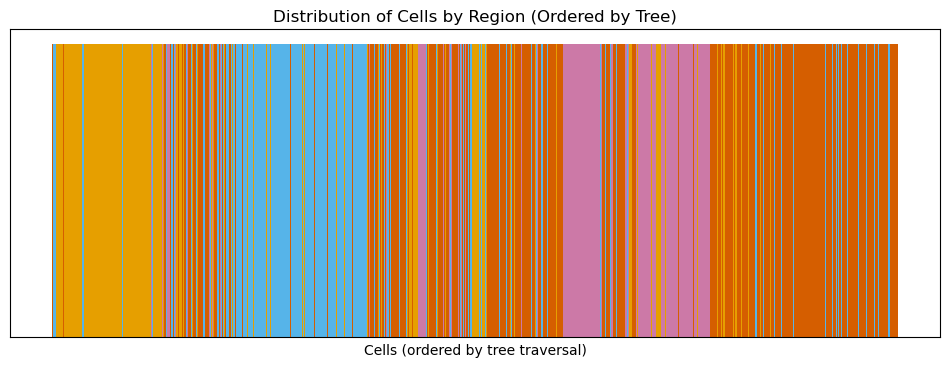

In [9]:
#good to use - takes 2 min to run 

import matplotlib.pyplot as plt
import seaborn as sns
from ete3 import Tree

# Load tree from file
tree_file = "rerooted_tree_no_germline.nwk"  # Update with your actual file path
t = Tree(tree_file, format=1)  # format=1 assumes branch lengths and support values are present

# Get the leaf order by pre-order traversal
leaves = [leaf.name for leaf in t.iter_leaves()]

# Extract region labels
regions = [leaf.split("_")[0] for leaf in leaves]  # Extract "neck15", "neck16", etc.
colors = [region_colors.get(region, "black") for region in regions]  # Get corresponding colors

# Create the histogram (bar plot)
plt.figure(figsize=(12, 4))
#sns.barplot(x=range(len(leaves)), y=[1] * len(leaves), hue=regions, palette=region_colors, dodge=False, legend=False, alpha=1, 
 #   edgecolor=None, rasterized=True)
for i, region in enumerate(regions):
    plt.bar(i, 1, color=region_colors[region], width=1.0, edgecolor="none", rasterized=True)

# Format the plot
plt.xticks([])  # Hide x-axis labels (too many)
plt.yticks([])  # Hide y-axis labels (we only care about color distribution)
plt.xlabel("Cells (ordered by tree traversal)")
plt.ylabel("")
plt.title("Distribution of Cells by Region (Ordered by Tree)")

# Remove legend title
#plt.legend(title="Region")
plt.savefig("trees/distribution_by_region_after_filt_and_root.pdf",
            format="pdf", dpi=300, bbox_inches="tight", facecolor="white")

plt.savefig("trees/distribution_by_region_after_filt_and_root.png",
            format="png", dpi=1000, bbox_inches="tight", facecolor="white")

# Show the plot
#plt.show()
